# Layer-wise Probing of BERT with SentEval Probing Tasks
### Introduction to Large Language Models — Assignment 11

**Question.** What does each encoder layer of BERT know about a sentence? We freeze a pretrained BERT-base
model, take the sentence representation produced by **each of its 12 encoder layers**, and train a simple
**logistic regression** classifier (a *probe*) on it. If a linear probe can predict a property from a layer's
representation, that layer encodes the property in an easily readable form.

**Probing tasks** (from SentEval, Conneau et al., 2018):

| Task | File | Property | Classes | Type |
|---|---|---|---|---|
| **SentLen** | `sentence_length.txt` | number of words in the sentence, in 6 length bins | 6 | surface |
| **BShift** | `bigram_shift.txt` | were two adjacent words swapped? (`I` = inverted, `O` = original) | 2 | syntactic |
| **SubjNum** | `subj_number.txt` | is the subject of the main clause singular (`NN`) or plural (`NNS`)? | 2 | semantic |

**Setup**
- **Data:** for each task, 50,000 sentences with an equal number from every class, split 90:10 into
  train and test with class balance kept (stratified split).
- **Encoder:** `bert-base-uncased` (12 layers, hidden size 768, 110M parameters), frozen and used only to
  extract features. It is the smallest standard BERT with 12 layers, and it is the model studied by
  Jawahar et al. (2019), so our per-layer numbers can be compared with theirs directly.
- **Sentence representation:** the mean of a layer's token vectors (mean pooling). The `[CLS]` vector is
  probed as well for comparison.
- **Probes:** 12 logistic regression models per task (one per layer), 36 in total, evaluated on the test set.
  The embedding layer (layer 0) is probed as an extra baseline.

**Reference results**
- **Conneau et al., 2018**, *What you can cram into a single \$&!#\* vector: Probing sentence embeddings
  for linguistic properties* (ACL 2018, [arXiv:1805.01070](https://arxiv.org/abs/1805.01070)). It defines the
  tasks and reports baselines and LSTM/ConvNet encoders. The arXiv ID in the assignment (1803.05449) is the
  companion *SentEval toolkit* paper by the same authors; the probing results are in 1805.01070.
- **Jawahar et al., 2019**, *What does BERT learn about the structure of language?* (ACL 2019). It runs the
  same probing tasks on every layer of BERT-base.

## 1. Setup

In [1]:
import os, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix
from transformers import AutoTokenizer, AutoModel

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

MODEL_NAME = "google-bert/bert-base-uncased"
N_SAMPLES = int(os.environ.get("LAB11_N_SAMPLES", 50_000))   # samples per task (env var only for quick tests)
TEST_SIZE = 0.10
MAX_LEN = 128
BATCH_SIZE = 128
PROBE_CLS = True          # also probe the [CLS] vector of every layer

DATA_DIR = "data"
ARTIFACTS_DIR = "lab11_artifacts"
FEATURE_DIR = f"{ARTIFACTS_DIR}/features"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", DEVICE, "| samples per task:", N_SAMPLES)

/opt/anaconda3/envs/nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | samples per task: 50000


## 2. Data

Each line of a SentEval probing file is `split <TAB> label <TAB> sentence`. The original files come with
their own train/dev/test split (`tr`/`va`/`te`), but the assignment asks for our own balanced 50k sample and a
90:10 split, so the original split column is ignored.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing"
TASKS = {"SentLen": "sentence_length.txt", "BShift": "bigram_shift.txt", "SubjNum": "subj_number.txt"}

def load_task(fname):
    path = f"{DATA_DIR}/{fname}"
    if not os.path.exists(path):
        print("downloading", fname)
        urllib.request.urlretrieve(f"{BASE_URL}/{fname}", path)
    df = pd.read_csv(path, sep="\t", header=None, names=["split", "label", "sentence"],
                     quoting=3, keep_default_na=False, dtype=str)
    return df

raw = {task: load_task(f) for task, f in TASKS.items()}
for task, df in raw.items():
    print(f"{task:8s} {len(df):7d} sentences | class counts: {df.label.value_counts().sort_index().to_dict()}")

SentLen   119988 sentences | class counts: {'0': 19998, '1': 19998, '2': 19998, '3': 19998, '4': 19998, '5': 19998}
BShift    120000 sentences | class counts: {'I': 60000, 'O': 60000}
SubjNum   120000 sentences | class counts: {'NN': 60000, 'NNS': 60000}


In [3]:
for task, df in raw.items():
    print(f"\n{task}")
    for lab in sorted(df.label.unique()):
        print(f"  {lab:>4s}: {df[df.label == lab].sentence.iloc[0]}")


SentLen
     0: But it was not here .
     1: Today was Tuesday , and that meant Bible class .
     2: He should leave the Bible here in the ditch by the cows .
     3: Not in this book , and not in anything that his parents had ever taught him about it .
     4: Oh , he was quite sure there was justice and virtue in the world , and he intended to find it .
     5: The boy fell to his knees on the sharp stones of the road and flung the grass aside , shaking so badly he could hardly breathe .

BShift
     I: A week she 'd been with the man , just a week , and she had survived barely the ups and downs .
     O: I hated even hearing that name now .

SubjNum
    NN: Coming from a xenophobic race that possesses the unique ability to pass among other species and chooses not to , the bounty hunter is a walking contradiction .
   NNS: Chills ran along her skin just thinking about the terrifying experience .


**SentLen bins.** The labels 0–5 are length bins. Counting words per class shows the bin boundaries
(Conneau et al. use 6 equal-width bins).

In [4]:
n_words = raw["SentLen"].sentence.str.split().str.len()
raw["SentLen"].assign(n_words=n_words).groupby("label").n_words.agg(["min", "max", "mean", "count"])

,min,max,mean,count
label,,,,
0,5,8,6.599010,19998
1,9,12,10.433143,19998
2,13,16,14.405341,19998
3,17,20,18.379638,19998
4,21,25,22.791929,19998
5,26,28,26.910541,19998


### Balanced 50k sample and stratified 90:10 split

From every task we draw the same number of sentences per class (`N_SAMPLES // n_classes`). SentLen has
6 classes, so it gets 8,333 per class = 49,998 sentences; BShift and SubjNum get 25,000 per class. The split
uses `stratify=label`, so train and test keep the class balance exactly.

In [5]:
splits = {}
rows = []
for task, df in raw.items():
    classes = sorted(df.label.unique())
    per_class = N_SAMPLES // len(classes)
    sample = df.groupby("label").sample(n=per_class, random_state=RANDOM_SEED).reset_index(drop=True)
    train_df, test_df = train_test_split(sample, test_size=TEST_SIZE, stratify=sample.label,
                                         random_state=RANDOM_SEED)
    splits[task] = (train_df.reset_index(drop=True), test_df.reset_index(drop=True), classes)
    for name, part in [("train", train_df), ("test", test_df)]:
        counts = part.label.value_counts().sort_index()
        rows.append({"task": task, "split": name, "size": len(part), **{f"class {c}": n for c, n in counts.items()}})

pd.DataFrame(rows).set_index(["task", "split"]).fillna("")

size class 0 class 1 class 2 class 3 class 4 class 5  class I  \
task    split                                                                   
SentLen train  44998  7500.0  7500.0  7500.0  7499.0  7499.0  7500.0            
        test    5000   833.0   833.0   833.0   834.0   834.0   833.0            
BShift  train  45000                                                  22500.0   
        test    5000                                                   2500.0   
SubjNum train  45000                                                            
        test    5000                                                            

               class O class NN class NNS  
task    split                              
SentLen train                              
        test                               
BShift  train  22500.0                     
        test    2500.0                     
SubjNum train           22500.0   22500.0  
        test             2500.0    2500.0

## 3. Extracting layer-wise sentence representations

BERT is run once over every sentence with `output_hidden_states=True`, which returns 13 hidden-state tensors:
the embedding output (layer 0) and the output of each of the 12 encoder layers. For each layer we keep:

- **mean pooling:** the average of the token vectors, excluding `[CLS]`, `[SEP]` and padding;
- **`[CLS]`:** the vector of the first token.

Sentences are processed in batches sorted by length to reduce padding. Features are stored as float16 `.npy` files
(`lab11_artifacts/features/`, shape `(13 layers, N, 768)`) and memory-mapped, so only the layer being probed is
loaded into RAM, and the probes can be rerun without running BERT again.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()
N_LAYERS = bert.config.num_hidden_layers          # 12
print(f"{MODEL_NAME}: {N_LAYERS} layers, hidden size {bert.config.hidden_size}, "
      f"{sum(p.numel() for p in bert.parameters()) / 1e6:.0f}M parameters")

ex = splits["BShift"][0].sentence.iloc[0]
print("\nexample:", ex)
print("tokens :", tokenizer.tokenize(ex))

W1115 16:37:52.219000 97006 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8976.45it/s]
[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


google-bert/bert-base-uncased: 12 layers, hidden size 768, 109M parameters

example: That 's these how things usually worked , at least .
tokens : ['that', "'", 's', 'these', 'how', 'things', 'usually', 'worked', ',', 'at', 'least', '.']


In [7]:
@torch.no_grad()
def extract_features(sentences):
    # returns mean-pooled and [CLS] features, each of shape (13 layers, N, 768), float16
    sentences = list(sentences)
    order = np.argsort([len(s) for s in sentences])
    n, d = len(sentences), bert.config.hidden_size
    mean_feats = np.zeros((N_LAYERS + 1, n, d), dtype=np.float16)
    cls_feats = np.zeros((N_LAYERS + 1, n, d), dtype=np.float16)
    for start in range(0, n, BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]
        enc = tokenizer([sentences[i] for i in idx], padding=True, truncation=True,
                        max_length=MAX_LEN, return_tensors="pt", return_special_tokens_mask=True)
        special = enc.pop("special_tokens_mask")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        hidden = torch.stack(bert(**enc, output_hidden_states=True).hidden_states, dim=1)  # (B, 13, T, d)
        mask = (enc["attention_mask"].bool() & ~special.to(DEVICE).bool()).float()          # (B, T)
        mask = mask[:, None, :, None]
        mean = (hidden * mask).sum(2) / mask.sum(2).clamp(min=1)
        mean_feats[:, idx] = mean.transpose(0, 1).float().cpu().numpy().astype(np.float16)
        cls_feats[:, idx] = hidden[:, :, 0].transpose(0, 1).float().cpu().numpy().astype(np.float16)
    return mean_feats, cls_feats


def get_features(task, part, sentences):
    # features are cached as .npy files and memory-mapped, so only the layer being probed is read into RAM
    paths = [f"{FEATURE_DIR}/{task}_{part}_{len(sentences)}_{rep}.npy" for rep in ("mean", "cls")]
    if not all(os.path.exists(p) for p in paths):
        for p, arr in zip(paths, extract_features(sentences)):
            np.save(p, arr)
            del arr
    return tuple(np.load(p, mmap_mode="r") for p in paths)


features = {}
for task, (train_df, test_df, classes) in splits.items():
    t0 = time.time()
    features[task] = {part: get_features(task, part, df.sentence) for part, df in [("train", train_df), ("test", test_df)]}
    print(f"{task:8s} train {features[task]['train'][0].shape} | test {features[task]['test'][0].shape} "
          f"| {time.time() - t0:.0f}s")
    if DEVICE == "mps":
        torch.mps.empty_cache()

SentLen  train (13, 44998, 768) | test (13, 5000, 768) | 228s
BShift   train (13, 45000, 768) | test (13, 5000, 768) | 191s
SubjNum  train (13, 45000, 768) | test (13, 5000, 768) | 219s


## 4. Training the probes

For every task and every layer we train a logistic regression classifier on the training features and report
accuracy on the test set. The features are standardised first (zero mean, unit variance), which makes
L-BFGS converge quickly. The regularisation strength is kept at the default `C = 1.0` for all probes, so
differences between layers come from the representations, not from tuning.

In [8]:
def train_probe(X_train, y_train, X_test, y_test):
    probe = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_SEED))
    probe.fit(X_train.astype(np.float32), y_train)
    return (accuracy_score(y_train, probe.predict(X_train.astype(np.float32))),
            accuracy_score(y_test, probe.predict(X_test.astype(np.float32))),
            probe)

results = []
probes = {}
t_all = time.time()
for task, (train_df, test_df, classes) in splits.items():
    y_train, y_test = train_df.label.values, test_df.label.values
    reps = ["mean", "cls"] if PROBE_CLS else ["mean"]
    for rep_i, rep in enumerate(reps):
        Xtr_all, Xte_all = features[task]["train"][rep_i], features[task]["test"][rep_i]
        layers = range(0, N_LAYERS + 1) if rep == "mean" else range(1, N_LAYERS + 1)
        for layer in layers:
            t0 = time.time()
            tr_acc, te_acc, probe = train_probe(Xtr_all[layer], y_train, Xte_all[layer], y_test)
            probes[(task, rep, layer)] = probe
            results.append({"task": task, "representation": rep, "layer": layer,
                            "train_acc": tr_acc, "test_acc": te_acc, "seconds": time.time() - t0})
        print(f"{task:8s} {rep:4s} done ({time.time() - t_all:.0f}s total)")

results = pd.DataFrame(results)
results.to_csv(f"{ARTIFACTS_DIR}/probing_results.csv", index=False)

SentLen  mean done (293s total)
SentLen  cls  done (883s total)
BShift   mean done (932s total)
BShift   cls  done (1025s total)
SubjNum  mean done (1063s total)
SubjNum  cls  done (1182s total)


## 5. Results

### Test accuracy (%) of the 12 layer-wise probes per task (mean pooling)

Layer 0 is the embedding layer (an extra baseline, not one of the 12 required models). The best encoder layer
of each task is listed after the table and marked with a star in the plot below.

In [9]:
mean_res = results[results.representation == "mean"]
table = (mean_res.pivot(index="layer", columns="task", values="test_acc")[list(TASKS)] * 100).round(2)
majority = {task: 100 / len(classes) for task, (_, _, classes) in splits.items()}
display(table)

best = (mean_res[mean_res.layer >= 1].sort_values("test_acc", ascending=False)
        .groupby("task").head(1).set_index("task").loc[list(TASKS)])
for task, row in best.iterrows():
    print(f"best layer for {task:8s}: layer {int(row.layer):2d} -> {row.test_acc * 100:.2f}% "
          f"(chance {majority[task]:.1f}%, train {row.train_acc * 100:.2f}%)")

task,SentLen,BShift,SubjNum
layer,,,
0,96.04,50.82,84.02
1,95.80,55.90,84.70
2,95.06,71.82,84.38
3,95.20,83.38,85.20
4,93.72,86.74,85.60
5,93.08,87.70,87.56
6,91.88,89.64,88.42
7,90.80,90.76,89.20
8,90.66,91.90,88.84


best layer for SentLen : layer  1 -> 95.80% (chance 16.7%, train 99.40%)
best layer for BShift  : layer  8 -> 91.90% (chance 50.0%, train 91.83%)
best layer for SubjNum : layer  7 -> 89.20% (chance 50.0%, train 89.49%)


### Comparison with the expected results

**Jawahar et al. (2019), Table 2:** probing accuracy of each BERT-base layer on the same tasks. They use the
SentEval toolkit with its hyper-parameter search for the probing classifier (an MLP, not a fixed logistic
regression), on the full SentEval data.

In [10]:
jawahar = pd.DataFrame({
    "SentLen": [93.9, 95.9, 96.2, 94.2, 92.0, 88.4, 83.7, 82.9, 80.1, 77.0, 73.9, 69.5],
    "BShift":  [50.3, 55.8, 64.9, 74.4, 81.4, 82.9, 83.0, 83.9, 87.0, 86.7, 86.8, 86.4],
    "SubjNum": [77.6, 82.5, 82.0, 81.9, 85.8, 88.1, 87.4, 87.5, 87.6, 87.1, 85.7, 84.0],
}, index=pd.Index(range(1, 13), name="layer"))

side = pd.concat({"ours (LR, mean pool)": table.loc[1:], "Jawahar et al. 2019": jawahar}, axis=1)
side = side.swaplevel(axis=1)[[(t, s) for t in TASKS for s in ["ours (LR, mean pool)", "Jawahar et al. 2019"]]]
side

task               SentLen                                   BShift  \
      ours (LR, mean pool) Jawahar et al. 2019 ours (LR, mean pool)   
layer                                                                 
1                    95.80                93.9                55.90   
2                    95.06                95.9                71.82   
3                    95.20                96.2                83.38   
4                    93.72                94.2                86.74   
5                    93.08                92.0                87.70   
6                    91.88                88.4                89.64   
7                    90.80                83.7                90.76   
8                    90.66                82.9                91.90   
9                    87.70                80.1                90.68   
10                   84.70                77.0                89.76   
11                   83.24                73.9                89.38   
12                   81.62                69.5                88.30   

task                                   SubjNum                      
      Jawahar et al. 2019 ours (LR, mean pool) Jawahar et al. 2019  
layer                                                               
1                    50.3                84.70                77.6  
2                    55.8                84.38                82.5  
3                    64.9                85.20                82.0  
4                    74.4                85.60                81.9  
5                    81.4                87.56                85.8  
6                    82.9                88.42                88.1  
7                    83.0                89.20                87.4  
8                    83.9                88.84                87.5  
9                    87.0                88.98                87.6  
10                   86.7                88.38                87.1  
11                   86.8                87.46                85.7  
12                   86.4                86.92                84.0

**Conneau et al. (2018), Table 2:** baselines and the best sentence encoders on the same tasks (test accuracy, %).

In [11]:
conneau = pd.DataFrame([
    ["Majority vote",                 20.0, 50.0, 50.0],
    ["Human evaluation",             100.0, 98.0, 88.0],
    ["Length (sentence length only)", 100.0, 50.6, 50.3],
    ["NB-bi-tfidf",                   23.0, 63.8, 69.1],
    ["BoV-fastText",                  66.6, 50.8, 82.1],
    ["BiLSTM-max, untrained",         73.3, 70.6, 85.8],
    ["BiLSTM-max, NMT En-Fr",         80.1, 73.7, 90.3],
    ["BiLSTM-max, NLI",               71.7, 65.1, 80.7],
    ["Gated ConvNet, Seq2Tree (best)", 96.5, 83.6, 94.5],
], columns=["model", "SentLen", "BShift", "SubjNum"]).set_index("model")

ours = pd.DataFrame({
    "BERT-base, best layer (ours)":  {t: best.loc[t, "test_acc"] * 100 for t in TASKS},
    "BERT-base, layer 12 (ours)":    {t: table.loc[12, t] for t in TASKS},
    "BERT-base, best layer (Jawahar)": jawahar.max().to_dict(),
}).T
comparison = pd.concat([conneau, ours]).round(1)
comparison.to_csv(f"{ARTIFACTS_DIR}/comparison_with_papers.csv")
comparison

,SentLen,BShift,SubjNum
Majority vote,20.0,50.0,50.0
Human evaluation,100.0,98.0,88.0
Length (sentence length only),100.0,50.6,50.3
NB-bi-tfidf,23.0,63.8,69.1
BoV-fastText,66.6,50.8,82.1
"BiLSTM-max, untrained",73.3,70.6,85.8
"BiLSTM-max, NMT En-Fr",80.1,73.7,90.3
"BiLSTM-max, NLI",71.7,65.1,80.7
"Gated ConvNet, Seq2Tree (best)",96.5,83.6,94.5
"BERT-base, best layer (ours)",95.8,91.9,89.2


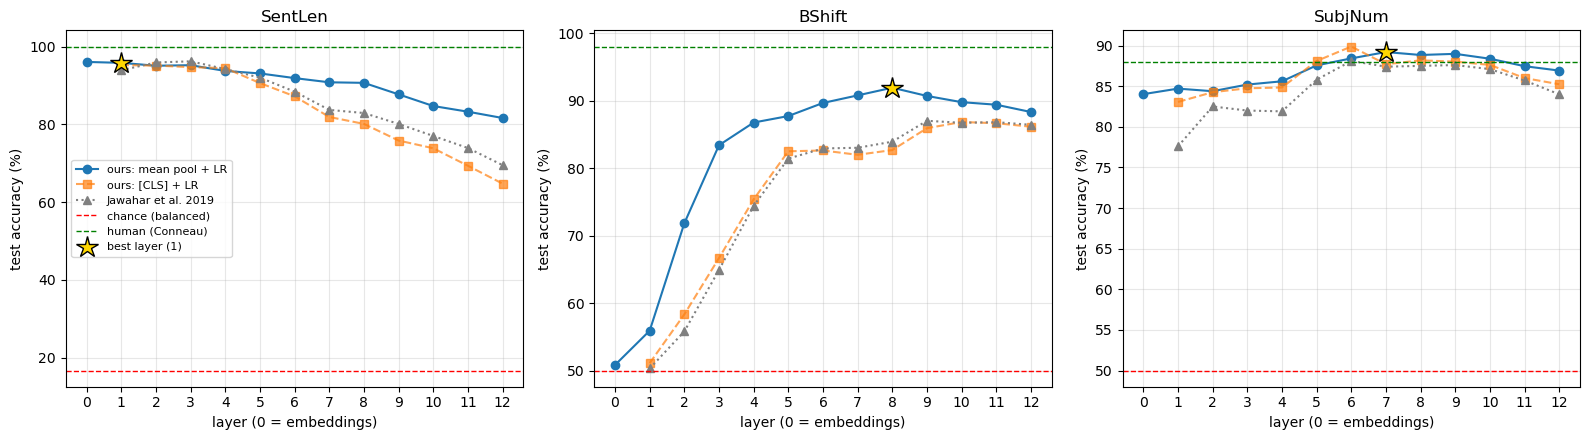

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
layers = np.arange(0, N_LAYERS + 1)
for ax, task in zip(axes, TASKS):
    ax.plot(layers, table[task], "o-", label="ours: mean pool + LR")
    if PROBE_CLS:
        cls_acc = results[(results.task == task) & (results.representation == "cls")].set_index("layer").test_acc * 100
        ax.plot(cls_acc.index, cls_acc, "s--", alpha=0.7, label="ours: [CLS] + LR")
    ax.plot(jawahar.index, jawahar[task], "^:", color="gray", label="Jawahar et al. 2019")
    ax.axhline(majority[task], color="red", lw=1, ls="--", label="chance (balanced)")
    ax.axhline(conneau.loc["Human evaluation", task], color="green", lw=1, ls="--", label="human (Conneau)")
    b = int(best.loc[task, "layer"])
    ax.plot(b, table.loc[b, task], "*", ms=16, color="gold", markeredgecolor="black", label=f"best layer ({b})")
    ax.set_title(task); ax.set_xlabel("layer (0 = embeddings)"); ax.set_xticks(layers)
    ax.set_ylabel("test accuracy (%)"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Mean pooling vs `[CLS]`

The pretrained `[CLS]` vector is trained only through next-sentence prediction, so it is expected to be a weaker
sentence summary than the average of all token vectors.

In [13]:
if PROBE_CLS:
    cls_table = (results[results.representation == "cls"]
                 .pivot(index="layer", columns="task", values="test_acc")[list(TASKS)] * 100).round(2)
    display(pd.concat({"mean pool": table.loc[1:], "[CLS]": cls_table}, axis=1)
            .swaplevel(axis=1)[[(t, r) for t in TASKS for r in ["mean pool", "[CLS]"]]])

task    SentLen           BShift          SubjNum       
      mean pool  [CLS] mean pool  [CLS] mean pool  [CLS]
layer                                                   
1         95.80  95.22     55.90  51.10     84.70  83.06
2         95.06  95.10     71.82  58.32     84.38  84.26
3         95.20  94.70     83.38  66.66     85.20  84.74
4         93.72  94.44     86.74  75.36     85.60  84.84
5         93.08  90.60     87.70  82.48     87.56  88.10
6         91.88  87.20     89.64  82.60     88.42  89.88
7         90.80  81.88     90.76  81.96     89.20  87.70
8         90.66  80.10     91.90  82.66     88.84  88.18
9         87.70  75.82     90.68  85.90     88.98  88.02
10        84.70  73.84     89.76  86.82     88.38  87.62
11        83.24  69.34     89.38  86.64     87.46  86.00
12        81.62  64.74     88.30  86.12     86.92  85.24

### Train vs test accuracy

A large gap between train and test accuracy would mean the probe memorises the training set instead of reading
a property that is really present in the representation.

In [14]:
gap = mean_res[mean_res.layer >= 1].pivot(index="layer", columns="task", values=["train_acc", "test_acc"]) * 100
gap = gap.swaplevel(axis=1)[[(t, s) for t in TASKS for s in ["train_acc", "test_acc"]]].round(2)
gap

task    SentLen             BShift            SubjNum         
      train_acc test_acc train_acc test_acc train_acc test_acc
layer                                                         
1         99.40    95.80     59.90    55.90     85.63    84.70
2         99.16    95.06     72.46    71.82     85.98    84.38
3         99.02    95.20     84.33    83.38     86.67    85.20
4         98.31    93.72     87.74    86.74     87.26    85.60
5         97.79    93.08     89.09    87.70     88.72    87.56
6         96.58    91.88     90.35    89.64     89.08    88.42
7         95.40    90.80     91.09    90.76     89.49    89.20
8         94.64    90.66     91.83    91.90     89.05    88.84
9         92.30    87.70     91.67    90.68     89.31    88.98
10        89.75    84.70     90.87    89.76     88.77    88.38
11        87.58    83.24     90.33    89.38     88.10    87.46
12        86.37    81.62     89.48    88.30     87.65    86.92

### SentLen: which length bins get confused?

Confusion matrices of the SentLen probe at its best layer and at the last layer.

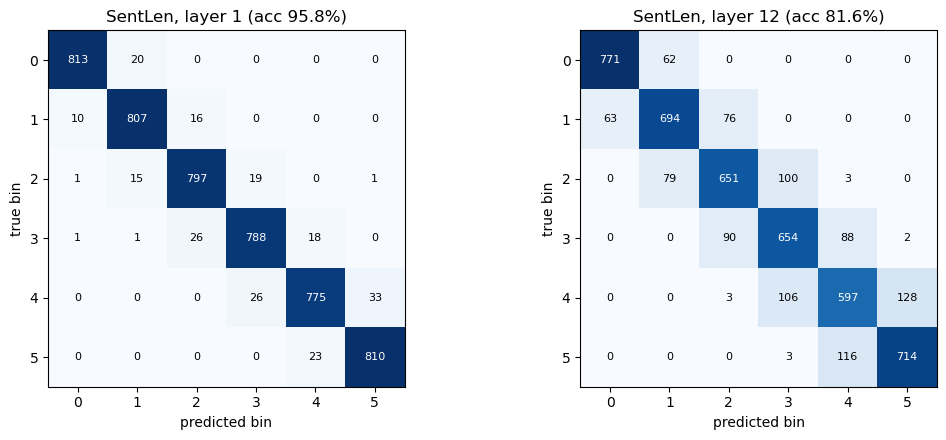

In [15]:
train_df, test_df, classes = splits["SentLen"]
b = int(best.loc["SentLen", "layer"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, layer in zip(axes, [b, N_LAYERS]):
    probe = probes[("SentLen", "mean", layer)]
    pred = probe.predict(features["SentLen"]["test"][0][layer].astype(np.float32))
    cm = confusion_matrix(test_df.label, pred, labels=classes)
    im = ax.imshow(cm, cmap="Blues")
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(len(classes)), classes); ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel("predicted bin"); ax.set_ylabel("true bin")
    ax.set_title(f"SentLen, layer {layer} (acc {accuracy_score(test_df.label, pred) * 100:.1f}%)")
plt.tight_layout(); plt.show()

## 6. Result analysis

- **BERT layers form a hierarchy.** Surface information is strongest at the bottom, and syntax and semantics in the middle. This matches Jawahar et al. (2019).
- **SentLen (surface):** best at the embedding layer and layer 1 (96.0 / 95.8%, chance 16.7%), then falls steadily to 81.6% at layer 12. Deeper layers mix the tokens into more abstract features and lose this simple property. The peak matches Jawahar (96.2%), but our drop at layer 12 is smaller (81.6 vs 69.5%).
- **BShift (syntax / word order):** near chance at layer 1 (55.9%). The embeddings carry no word order, because mean pooling ignores position, so order must be built by attention. Accuracy climbs to a peak of **91.9% at layer 8** and stays high. This beats Jawahar (87.0%) and every encoder in Conneau et al. (best 83.6%).
- **SubjNum (semantics):** already 84.7% at layer 1, since the noun's plural form is visible in the subword pieces. It peaks at **89.2% at layer 7**, above Jawahar (88.1%) and human annotators (88.0%), and below only Conneau's Seq2Tree (94.5%), which was trained with parse trees.
- **Mean pooling beats `[CLS]`** at almost every layer, especially for SentLen in the top layers (81.6 vs 64.7% at layer 12). The pretrained `[CLS]` vector only learns next-sentence prediction, so it is a poor sentence summary without fine-tuning.
- **No overfitting:** train and test accuracy are within about 1 point for BShift and SubjNum. SentLen has a 3.6–5 point gap, but test accuracy is still high.
- **For downstream use:** the middle layers (about 7–9) are the best general-purpose features. The last layer is slightly worse on every task, being specialised for the masked-word pretraining objective.